# Sistema inteligente de monitorización y diagnóstico industrial

**Programación de Inteligencia Artificial** · Práctica evaluable

Este cuaderno recorre la práctica paso a paso, explicando cada decisión.
**No contiene la lógica**: importa las funciones de `src/`, que es el mismo código que ejecuta `main.py`
(el entregable oficial). Así el cálculo existe en un único sitio y el cuaderno solo lo narra.

| Pieza | Papel |
| --- | --- |
| `src/` | Toda la lógica, un módulo por fase |
| `main.py` | Ejecuta la práctica completa de principio a fin (entregable) |
| Este cuaderno | Explica y muestra cada paso, con los gráficos en línea |

In [1]:
from pathlib import Path

import numpy as np
from IPython.display import Image, display

from src import analisis, carga, clasificador, evaluacion, graficos, limpieza, preparacion

RUTA_DATOS = Path("datos") / "sensores.csv"
RUTA_GRAFICOS = Path("resultados") / "graficos"
np.set_printoptions(suppress=True, precision=3, linewidth=120)

## Apartado 1 · Carga y exploración

**Objetivo:** cargar el CSV en arrays de NumPy, comprobar que es correcto y conocer su estructura.

**Decisiones clave:**
- `np.genfromtxt` en lugar de `np.loadtxt`: convierte cada celda vacía en `np.nan`, así los ausentes quedan marcados dentro del array. `loadtxt` falla con una celda vacía.
- Tres arrays según su papel: `ids` (texto), `mediciones` (matriz `float` de 4 columnas, la X) y `estados` (enteros, la y). Un array de NumPy tiene un solo tipo; mezclar texto y números obligaría a usar `dtype=object` y se perdería la vectorización.
- El `estado` se lee como `float` y después se convierte a `int`: con `dtype=int`, una celda vacía se convertiría en −1 sin ningún aviso.

In [2]:
datos = carga.cargar_datos(RUTA_DATOS)

print("ids       ", datos.ids.shape, datos.ids.dtype)
print("mediciones", datos.mediciones.shape, datos.mediciones.dtype)
print("estados   ", datos.estados.shape, datos.estados.dtype)

ids        (750,) <U5
mediciones (750, 4) float64
estados    (750,) int64


In [3]:
carga.mostrar_resumen(carga.resumen_exploratorio(datos))

Dimensiones: 750 registros x 6 columnas
Variables predictoras: temperatura, vibracion, consumo, presion
Tipos: id=<U5, mediciones=float64, estado=int64

Valores ausentes por variable:
  temperatura    15 (2.0%)
  vibracion      18 (2.4%)
  consumo        19 (2.5%)
  presion        23 (3.1%)
  Registros con al menos un ausente: 73 (9.7%)

Registros por estado:
  0 - Normal                250 (33.3%)
  1 - Desgaste mecánico     250 (33.3%)
  2 - Sobrecalentamiento    250 (33.3%)


In [4]:
carga.mostrar_muestra(datos, n=5)

id       temperatura    vibracion      consumo      presion   estado
S0001         71.423        1.123       25.515        5.431        0
S0002        116.375        2.209       27.219        6.616        2
S0003        -35.000        1.242       16.053        5.107        0
S0004         63.896        4.702       23.308        5.716        1
S0005         83.924        7.018       12.241        4.831        1


### Concepto: `axis`

`axis` indica qué dimensión se **colapsa** al operar:
- `axis=0` colapsa las filas, así que da un resultado **por columna** (por sensor).
- `axis=1` colapsa las columnas, así que da un resultado **por fila** (por registro).

In [5]:
ausentes = np.isnan(datos.mediciones)          # matriz (750, 4) de True/False

print("Huecos por sensor   (axis=0):", ausentes.sum(axis=0))
print("Registros con hueco (axis=1):", ausentes.any(axis=1).sum())

Huecos por sensor   (axis=0): [15 18 19 23]
Registros con hueco (axis=1): 73


**Conclusión:** 750 registros con las clases perfectamente equilibradas (250 por clase), así que el *accuracy* será una métrica fiable.
Hay 75 celdas vacías repartidas en 73 filas (9,7 %): borrarlas todas supondría perder casi un 10 % de los datos.

## Apartado 2 · Limpieza y preparación

**Criterio general:** si un valor es *imposible*, es un error; si es *raro pero posible*, puede ser una anomalía real y se conserva.

| Situación | Tratamiento |
| --- | --- |
| Valor fuera del rango físico | Se convierte en `nan` y se trata como ausente (el resto de la fila es válido) |
| Atípico estadístico dentro del rango | Se conserva y se informa |
| Fila con 2 o más valores por rellenar | Se descarta: la mitad de la fila sería inventada |
| Celda vacía | Se rellena en el apartado 4 con la mediana del **entrenamiento** (sin fuga de datos) |

In [6]:
resultado = limpieza.limpiar(datos)
limpieza.mostrar_resumen_limpieza(datos, resultado)

Valores ausentes en el CSV: 75 celdas en 73 registros

Errores de medición (fuera de rango físico): 11 -> se marcan como ausentes
  S0003  temperatura    -35.00   admisible [0, 150]
  S0037  presion         -3.00   admisible [0, 12]
  S0130  vibracion       -2.50   admisible [0, 15]
  S0149  temperatura    245.00   admisible [0, 150]
  S0168  vibracion       -0.80   admisible [0, 15]
  S0171  vibracion       38.00   admisible [0, 15]
  S0396  temperatura    -18.00   admisible [0, 150]
  S0414  consumo         -1.50   admisible [0, 65]
  S0590  consumo         -4.00   admisible [0, 65]
  S0724  presion         28.00   admisible [0, 12]
  S0728  presion         -1.20   admisible [0, 12]

Decisión por registro:
  Válidos sin cambios:              666
  A corregir (1 valor a imputar):    82
  Descartados (2+ valores):           2  ['S0236', 'S0641']
  Conservados:                      748

Atípicos estadísticos (IQR x1.5) dentro del rango físico -> se CONSERVAN:
  variable      global  por

### ¿Por qué el IQR se calcula dentro de cada clase?

Si el IQR se calcula sobre todo el dataset, se marcan como "atípicas" las vibraciones altas.
Pero una vibración alta es justo la **señal del desgaste**. Veamos de qué clase son esos atípicos:

In [7]:
vibracion_atipica_global = resultado.atipicos_globales[:, 1]
por_estado = [int(vibracion_atipica_global[datos.estados == e].sum()) for e in (0, 1, 2)]
print("Vibraciones atípicas (IQR global) por estado 0/1/2:", por_estado)

Vibraciones atípicas (IQR global) por estado 0/1/2: [0, 14, 4]


La mayoría son de la clase 1 (desgaste): el criterio global trataría como ruido justo el patrón que queremos aprender.
Por eso los atípicos se buscan dentro de cada clase.

In [8]:
datos_limpios = resultado.datos
print("Registros conservados:", len(datos_limpios.ids))
print("Huecos pendientes de imputar (apartado 4):", int(np.isnan(datos_limpios.mediciones).sum()))

Registros conservados: 748
Huecos pendientes de imputar (apartado 4): 82


## Apartado 3 · Análisis estadístico

**Decisiones:**
- Se analizan los datos **limpios sin imputar**, con funciones que ignoran los `nan` (`np.nanmean`, `np.nanpercentile`…): se describen solo valores realmente medidos.
- La desviación estándar es **muestral** (`ddof=1`, corrección de Bessel): los registros son una muestra del comportamiento de las máquinas.
- Para medir qué variable distingue los estados se usan dos medidas: el **estadístico F** (una nota global por variable) y la **d de Cohen** por pareja de clases (qué separa cada variable).

In [9]:
X, y, variables = datos_limpios.mediciones, datos_limpios.estados, datos_limpios.variables

print("Estadísticos globales:")
analisis.mostrar_estadisticos(analisis.calcular_estadisticos(X), variables)

Estadísticos globales:
               temperatura   vibracion     consumo     presion
  media              83.02        3.42       22.55        6.06
  mediana            78.50        3.03       21.76        6.10
  desviacion         19.60        1.72        6.36        1.11
  minimo             41.09        0.05        6.93        1.22
  maximo            143.20       10.51       53.92       10.02
  q1                 67.76        2.15       18.11        5.36
  q3                 97.61        4.35       26.17        6.73
  iqr                29.85        2.20        8.06        1.36


La temperatura global tiene una media de 83,0 y una mediana de 78,5. No hay ningún sensor raro: el grupo de sobrecalentamiento arrastra la media.
Las estadísticas globales mezclan tres poblaciones distintas, así que lo que de verdad sirve es comparar **por clase**:

In [10]:
analisis.mostrar_comparativa_por_clase(*analisis.estadisticos_por_clase(X, y), variables)


  TEMPERATURA
                            Normal   Desgaste mecánico  Sobrecalentamiento
  media                      67.82               76.98              104.33
  mediana                    68.07               77.31              104.82
  desviacion                 10.24               12.27               13.22
  minimo                     41.09               46.44               66.28
  maximo                    131.41              123.26              143.20
  q1                         60.80               67.77               95.94
  q3                         74.32               84.37              112.66
  iqr                        13.52               16.59               16.72

  VIBRACION
                            Normal   Desgaste mecánico  Sobrecalentamiento
  media                       2.07                5.08                3.14
  mediana                     2.10                5.11                3.03
  desviacion                  0.68                1.47                1.

### ¿Qué variable distingue cada estado?

- **F (ANOVA)** = varianza *entre* clases / varianza *dentro* de las clases. Cuanto más alto, mejor separa la variable las tres clases a la vez.
- **d de Cohen** = |media_a − media_b| / desviación conjunta. Mide la distancia entre dos clases en desviaciones estándar; si es mayor que 0,8, la separación es grande.

In [11]:
parejas, d = analisis.d_cohen_por_pareja(X, y)
analisis.mostrar_separabilidad(analisis.ratio_f(X, y), parejas, d, variables)

  Estadístico F (ANOVA), de mayor a menor capacidad de separar las 3 clases:
    temperatura     615.9
    vibracion       400.2
    consumo         233.3
    presion          20.9

  d de Cohen por pareja de estados (> 0.8 = separación grande):
                  0 vs 1    0 vs 2    1 vs 2
  temperatura       0.81      3.09      2.14
  vibracion         2.63      1.05      1.41
  consumo           0.87      1.94      1.10
  presion           0.60      0.45      0.07

  Conclusiones:
    Normal vs Desgaste mecánico: la separa mejor 'vibracion' (d=2.63); variables con separación grande: ['temperatura', 'vibracion', 'consumo']
    Normal vs Sobrecalentamiento: la separa mejor 'temperatura' (d=3.09); variables con separación grande: ['temperatura', 'vibracion', 'consumo']
    Desgaste mecánico vs Sobrecalentamiento: la separa mejor 'temperatura' (d=2.14); variables con separación grande: ['temperatura', 'vibracion', 'consumo']
    Sin separación grande en ninguna pareja: ['presion']


### Gráficos

Se generan con `src/graficos.py`, se guardan en `resultados/graficos/` y se muestran aquí.
Cada estado tiene siempre el mismo color, comprobado para que se distinga también con daltonismo.

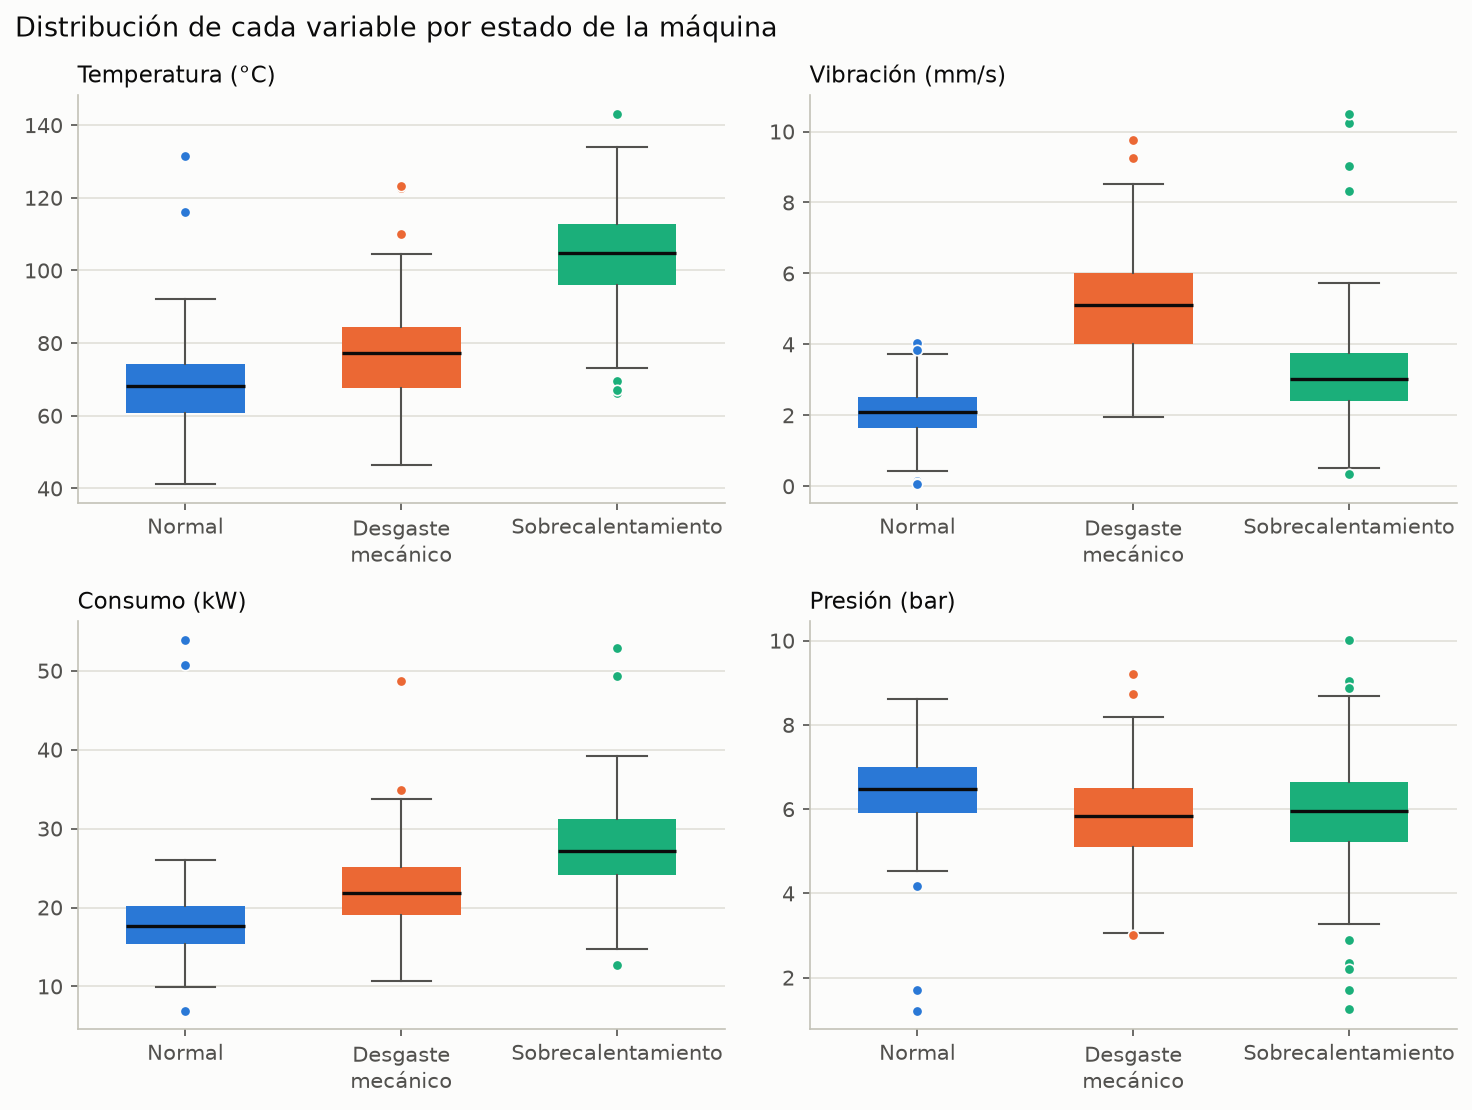

In [12]:
ruta = graficos.boxplots_por_clase(X, y, carga.NOMBRES_LEGIBLES, carga.UNIDADES, RUTA_GRAFICOS)
display(Image(filename=ruta))

**Lectura:** en temperatura, la caja de sobrecalentamiento no se solapa con las otras dos. En vibración, la de desgaste queda por encima de las demás.
En presión, las tres cajas están a la misma altura: no distingue. Los puntos sueltos son los atípicos de cada clase (`whis=1.5`, el mismo criterio que en el apartado 2).

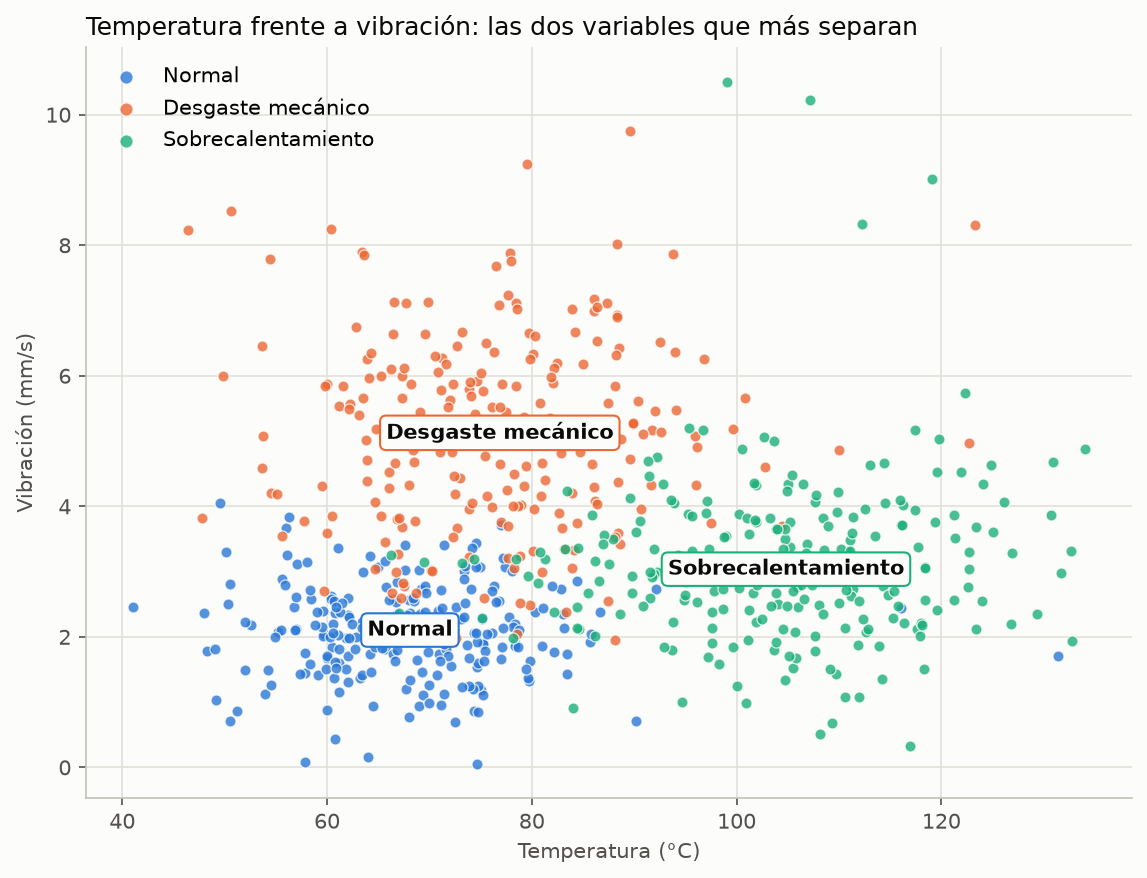

In [13]:
ruta = graficos.dispersion(X, y, carga.NOMBRES_LEGIBLES, carga.UNIDADES, RUTA_GRAFICOS)
display(Image(filename=ruta))

**Lectura:** tres nubes de puntos (normal abajo a la izquierda, desgaste arriba, sobrecalentamiento a la derecha) que se mezclan en la zona de 75–90 °C y 2,5–4 mm/s.
Ahí es donde el clasificador cometerá errores.

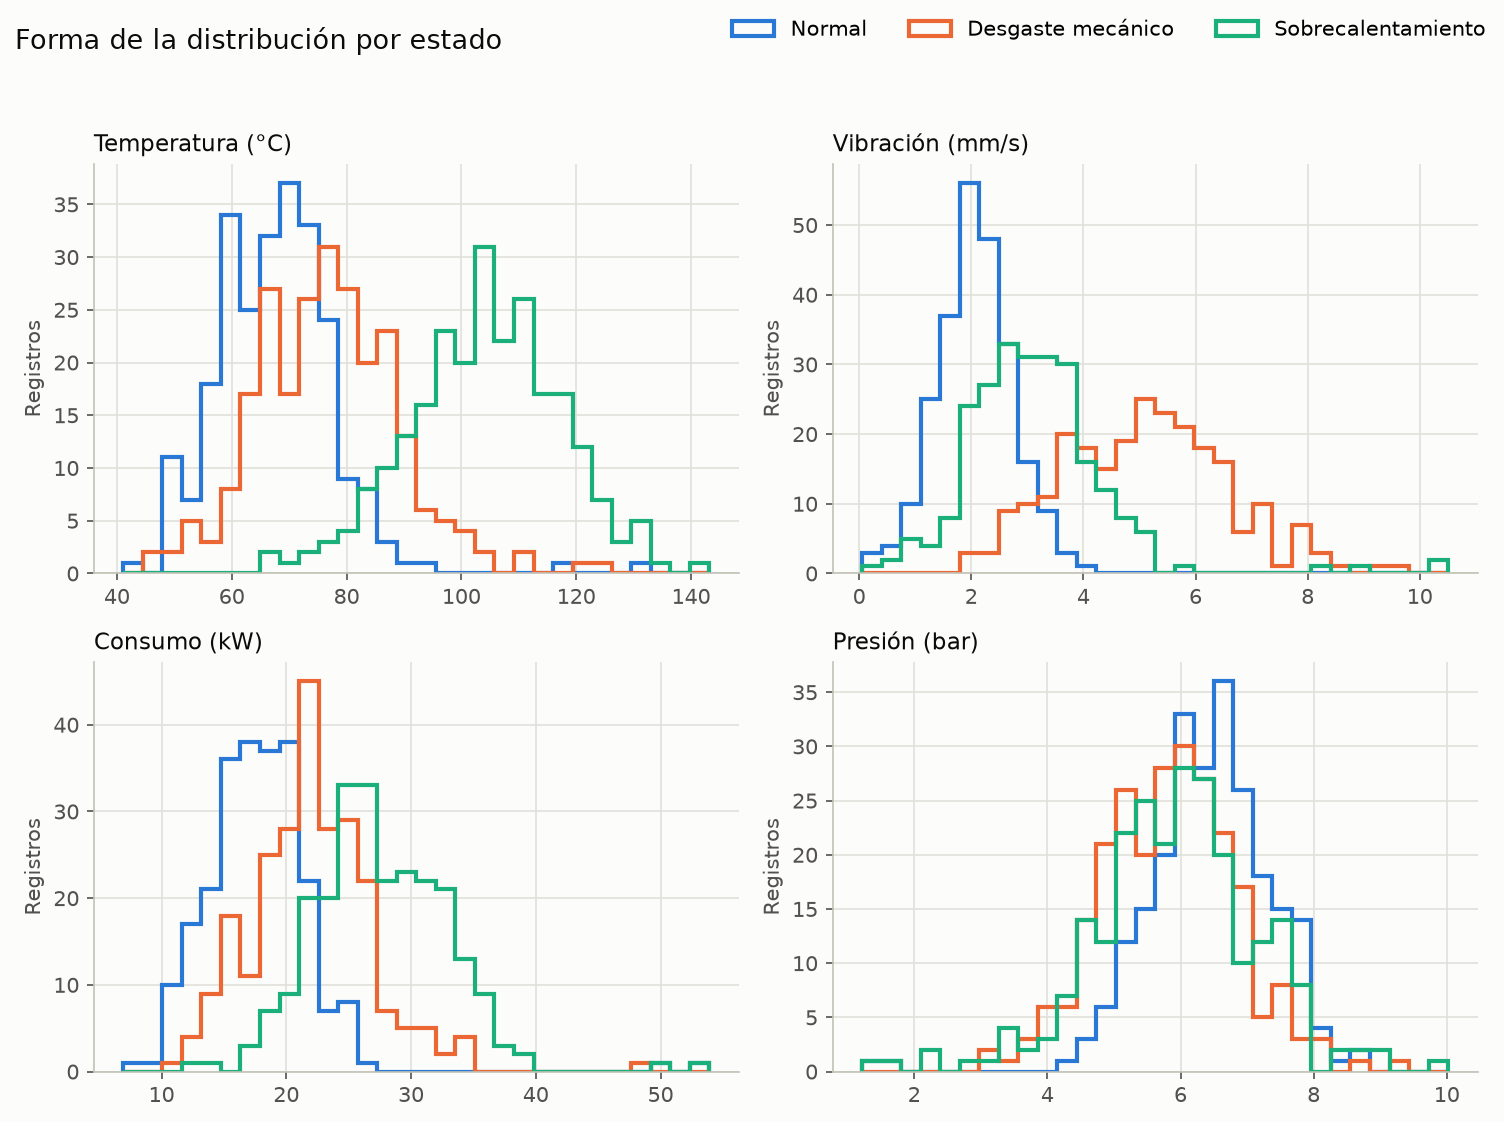

In [14]:
ruta = graficos.histogramas_por_clase(X, y, carga.NOMBRES_LEGIBLES, carga.UNIDADES, RUTA_GRAFICOS)
display(Image(filename=ruta))

**Lectura:** cada clase tiene forma de campana más o menos simétrica, así que la media representa bien a cada clase, y eso es lo que usará el clasificador de centroides.
En presión, las tres curvas se superponen casi por completo.

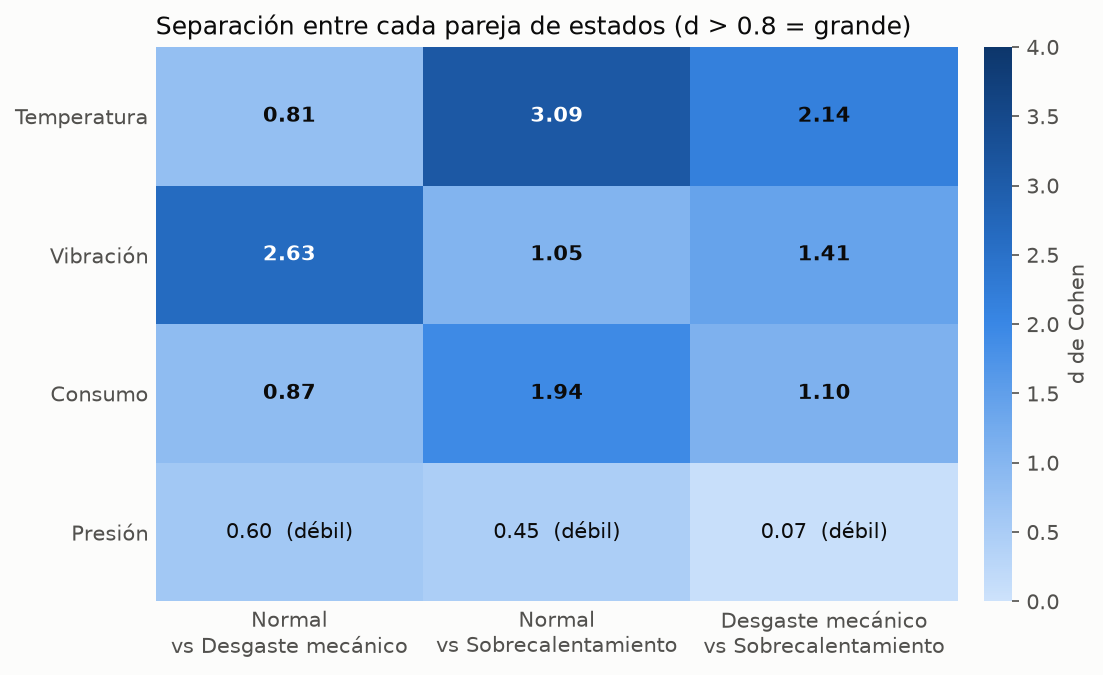

In [15]:
ruta = graficos.mapa_calor_cohen(d, parejas, carga.NOMBRES_LEGIBLES, RUTA_GRAFICOS)
display(Image(filename=ruta))

**Conclusiones del apartado 3:**
1. La **temperatura** separa el sobrecalentamiento y la **vibración** separa el desgaste; el **consumo** ayuda de forma moderada.
2. La **presión** apenas aporta, pero después de normalizar pesará lo mismo que las demás en la distancia euclídea. Es una limitación que hay que señalar.
3. La pareja **normal–desgaste** es la más difícil (solo la vibración las distingue). Se espera que ahí se concentren los errores del apartado 6.

## Apartado 4 · Transformación y normalización

**Orden de las operaciones.** Todas las estadísticas salen **solo** del entrenamiento:
1. División estratificada 80/20: cada clase se reparte por separado, con semilla fija (42) para que el resultado sea reproducible.
2. Huecos rellenados con la **mediana del entrenamiento**.
3. Normalización z-score: `z = (x − media) / desviación`, con la media y la desviación (`ddof=1`) del entrenamiento.

El conjunto de prueba hace el papel de **datos futuros**: recibe exactamente la misma transformación, pero nunca participa en calcularla.

In [16]:
particion = preparacion.dividir_estratificado(datos_limpios)
transformacion = preparacion.ajustar_transformacion(particion.X_entrenamiento)   # solo ve el entrenamiento

X_entrenamiento = preparacion.transformar(particion.X_entrenamiento, transformacion)
X_prueba = preparacion.transformar(particion.X_prueba, transformacion)        # misma transformación
y_entrenamiento, y_prueba = particion.y_entrenamiento, particion.y_prueba

preparacion.mostrar_resumen_preparacion(particion, transformacion, X_entrenamiento, X_prueba, variables)

Variables predictoras (X): temperatura, vibracion, consumo, presion  |  variable objetivo (y): estado
Entrenamiento: 598 registros (79.9%)   Prueba: 150 registros (20.1%)

Distribución de clases (estratificación):
  entrenamiento  0=199 (33.3%), 1=200 (33.4%), 2=199 (33.3%)
  prueba         0=50 (33.3%), 1=50 (33.3%), 2=50 (33.3%)
  Registros presentes en ambas partes: 0

Huecos imputados con la mediana del entrenamiento:
  entrenamiento: 68   prueba: 14

Parámetros aprendidos del entrenamiento:
                temperatura    vibracion      consumo      presion
  mediana            78.770        3.070       21.679        6.091
  media              82.953        3.438       22.512        6.065
  desviacion         19.375        1.733        6.408        1.091

Comprobación tras normalizar (media y desviación por variable):
  entrenamiento  media=[0. 0. 0. 0.]  desviación=[1. 1. 1. 1.]
  prueba         media=[-0.007 -0.069  0.013 -0.042]  desviación=[1.011 0.904 0.895 0.991]
  (el entren

### ¿Por qué la prueba no queda exactamente en media 0 y desviación 1?

Porque se normaliza con los parámetros del **entrenamiento**, no con los suyos. Si quedara exacta, significaría que se han usado sus propias estadísticas, es decir, que habría **fuga de datos**.
Que salga cerca de 0 y 1 indica que las dos particiones vienen de la misma distribución, que es justo lo que busca la estratificación.

### ¿Por qué normalizar?

El clasificador del apartado 5 mide distancias euclídeas. Sin normalizar, la temperatura (desviación ≈ 19) dominaría sobre la vibración (desviación ≈ 1,7) solo por estar en otra escala.
Tras el z-score, cada variable se mide en "desviaciones estándar" y todas pesan igual. Esa es también la limitación de la presión que vimos en el apartado 3: ahora pesa lo mismo que las demás.

In [17]:
print("Rango de cada variable ANTES de normalizar (entrenamiento imputado):")
X_ent_imputado = preparacion.imputar(particion.X_entrenamiento, transformacion.medianas)
print("  ", np.ptp(X_ent_imputado, axis=0).round(2), "  <- escalas muy distintas")
print("Rango DESPUÉS de normalizar:")
print("  ", np.ptp(X_entrenamiento, axis=0).round(2), "  <- todas comparables")

Rango de cada variable ANTES de normalizar (entrenamiento imputado):
   [102.11  10.46  43.94   8.81]   <- escalas muy distintas
Rango DESPUÉS de normalizar:
   [5.27 6.03 6.86 8.07]   <- todas comparables


## Apartado 5 · Clasificador de centroide más cercano

**Idea:** cada clase se resume en su punto medio (**centroide**). Una medición nueva se asigna a la clase cuyo centroide tenga más cerca.

1. **Entrenar** = calcular la media de cada clase con `X_entrenamiento`, ya normalizado.
2. **Predecir** = distancia euclídea de cada punto a los 3 centroides; gana la menor (`argmin`).

**Variables:** se usan las 4. La validación cruzada sobre el entrenamiento (apartado 6) da 0,888 ± 0,027 con las 4 y 0,893 ± 0,018 sin la presión: la diferencia está dentro del ruido entre pliegues, así que no compensa complicar el modelo.

### Entrenar: centroides con una multiplicación de matrices

La matriz de **pertenencia** (one-hot) tiene un 1 en `[i, c]` si la observación `i` es de la clase `c`.
`pertenencia.T @ X` suma de una vez las observaciones de cada clase; al dividir entre el tamaño de cada clase se obtiene la media.

In [18]:
modelo = clasificador.entrenar(X_entrenamiento, y_entrenamiento)
clasificador.mostrar_modelo(modelo, variables, transformacion.media, transformacion.desviacion)

Centroides en unidades normalizadas (z):
                        temperatura    vibracion      consumo      presion
  Normal                     -0.776       -0.782       -0.700        0.319
  Desgaste mecánico          -0.307        0.935       -0.061       -0.134
  Sobrecalentamiento          1.085       -0.158        0.761       -0.184

Centroides en unidades originales:
                        temperatura    vibracion      consumo      presion
  Normal                      67.92         2.08        18.03         6.41
  Desgaste mecánico           77.00         5.06        22.12         5.92
  Sobrecalentamiento         103.97         3.16        27.39         5.87


Leídos en unidades reales, los centroides tienen sentido físico: el **sobrecalentamiento** está en unos 104 °C y el **desgaste** vibra a unos 5 mm/s.
Coinciden con lo que se vio en el apartado 3.

### Predecir: distancias con broadcasting en 3D

`X[:, None, :] - centroides[None, :, :]` combina una matriz (150, 1, 4) con otra (1, 3, 4) y produce un array (150, 3, 4) con **todas** las diferencias a la vez.
Después se eleva al cuadrado, se suma por variable (`axis=2`) y se saca la raíz: una matriz (150, 3) de distancias, sin ningún bucle.

In [19]:
diferencias = X_prueba[:, np.newaxis, :] - modelo.centroides[np.newaxis, :, :]
print("Forma de las diferencias:", diferencias.shape, " -> (puntos, centroides, variables)")

predicciones, distancias = clasificador.predecir(modelo, X_prueba)
print("Forma de las distancias:  ", distancias.shape, "    -> (puntos, centroides)\n")
clasificador.mostrar_predicciones(particion.ids_prueba, y_prueba, predicciones, distancias, modelo.clases)

Forma de las diferencias: (150, 3, 4)  -> (puntos, centroides, variables)
Forma de las distancias:   (150, 3)     -> (puntos, centroides)

Predicciones generadas: 150  ->  Normal=55, Desgaste mecánico=45, Sobrecalentamiento=50

Primeras 8 predicciones (distancia a cada centroide; gana la menor):
  id          d_0     d_1     d_2              predicho                  real
  S0304     0.354   1.807   2.549                Normal                Normal
  S0739     2.324   1.397   1.827     Desgaste mecánico     Desgaste mecánico
  S0282     2.597   1.150   2.873     Desgaste mecánico     Desgaste mecánico
  S0042     2.297   1.720   1.750     Desgaste mecánico    Sobrecalentamiento   <- fallo
  S0684     1.291   2.503   3.624                Normal                Normal
  S0068     0.719   2.265   2.605                Normal                Normal
  S0044     0.842   1.498   2.113                Normal                Normal
  S0514     1.707   1.924   2.936                Normal     Desgaste

### Comprobación: un ejemplo calculado a mano

In [20]:
x, c0 = X_prueba[0], modelo.centroides[0]
print(f"{particion.ids_prueba[0]}: d0 = sqrt(sum((x - c0)^2)) =", round(float(np.sqrt(((x - c0) ** 2).sum())), 4))
print("Calculada por el clasificador:      ", round(float(distancias[0, 0]), 4))

S0304: d0 = sqrt(sum((x - c0)^2)) = 0.3542
Calculada por el clasificador:       0.3542


Predicciones almacenadas en resultados/predicciones.csv


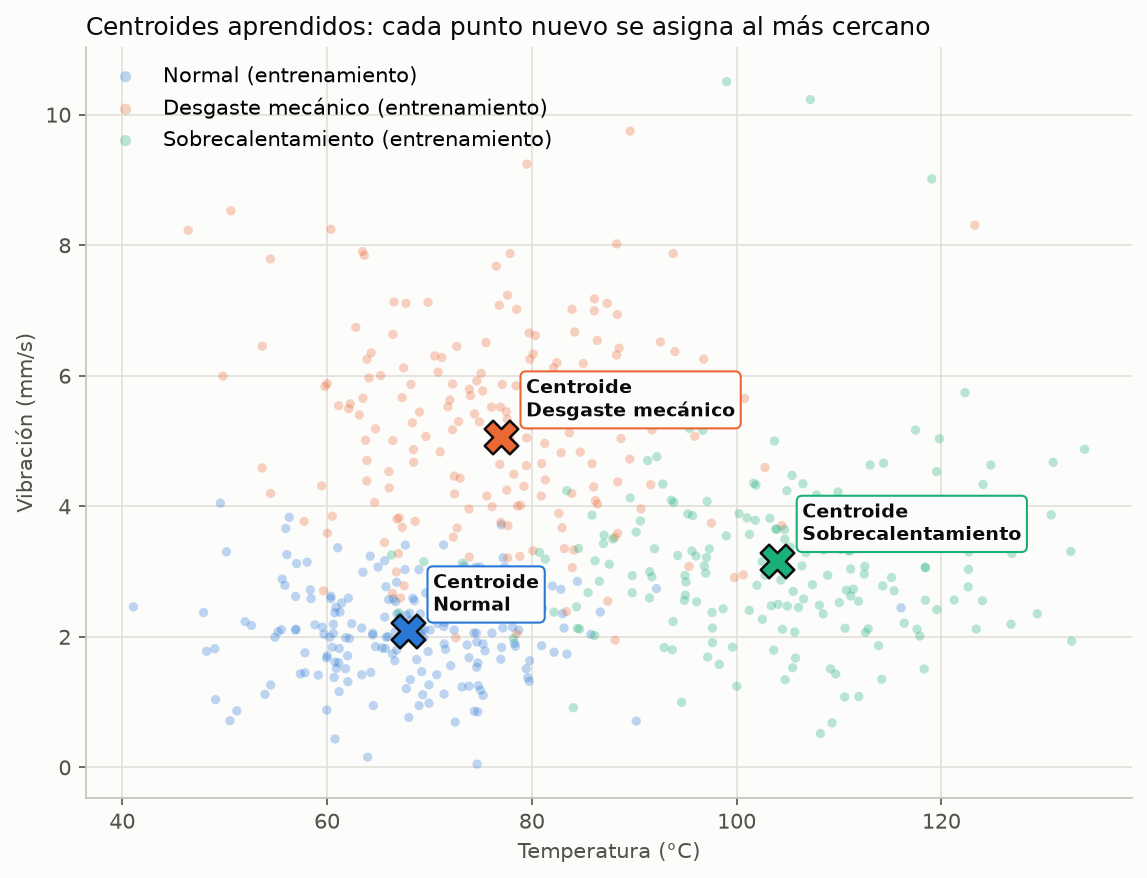

In [21]:
ruta = clasificador.guardar_predicciones(Path("resultados") / "predicciones.csv", particion.ids_prueba, y_prueba,
                                         predicciones, distancias, modelo.clases)
print("Predicciones almacenadas en", ruta)

ruta = graficos.centroides(particion.X_entrenamiento, y_entrenamiento,
                           modelo.centroides * transformacion.desviacion + transformacion.media,
                           modelo.clases, carga.NOMBRES_LEGIBLES, carga.UNIDADES, RUTA_GRAFICOS)
display(Image(filename=ruta))

**Ojo al leer el gráfico:** muestra 2 de las 4 variables y en unidades reales, mientras que el modelo decide en 4 dimensiones normalizadas.
Por eso algún punto puede parecer más cerca de otro centroide. Las decisiones del modelo se evalúan con métricas en el apartado 6.

## Apartado 6 · Evaluación del clasificador

Todas las métricas se calculan **a mano con NumPy**. Convención: **filas = estado real, columnas = estado predicho**.

- **Accuracy** = aciertos / total.
- **Precision de c** = de lo que se *predijo* como c, cuánto lo era (columna c).
- **Recall de c** = de lo que *era* c, cuánto se detectó (fila c).
- **F1** = media armónica de las dos: 2·P·R / (P + R). Castiga que una de ellas sea baja.

### La matriz de confusión con `np.bincount`

Cada pareja (real, predicho) se convierte en un número de celda único, `real × 3 + predicho`, entre 0 y 8.
`np.bincount` cuenta cuántas veces aparece cada número y `reshape(3, 3)` lo coloca en la matriz. No hace falta ningún bucle.

In [22]:
celda = y_prueba * 3 + predicciones
print("Primeras parejas (real, predicho):", list(zip(y_prueba[:6].tolist(), predicciones[:6].tolist())))
print("Su número de celda:               ", celda[:6].tolist())
print("Recuento por celda:", np.bincount(celda, minlength=9).tolist())
print(np.bincount(celda, minlength=9).reshape(3, 3))

Primeras parejas (real, predicho): [(0, 0), (1, 1), (1, 1), (2, 1), (0, 0), (0, 0)]
Su número de celda:                [0, 4, 4, 7, 0, 0]
Recuento por celda: [48, 1, 1, 7, 40, 3, 0, 4, 46]
[[48  1  1]
 [ 7 40  3]
 [ 0  4 46]]


In [23]:
metricas = evaluacion.calcular_metricas(y_prueba, predicciones)
evaluacion.mostrar_metricas(metricas)

Matriz de confusión (filas = real, columnas = predicho):
                                    Normal   Desgaste mecánico  Sobrecalentamiento
  Normal                                48                   1                   1
  Desgaste mecánico                      7                  40                   3
  Sobrecalentamiento                     0                   4                  46

Accuracy: 0.893  (134 aciertos de 150)

                        precision   recall      f1  soporte
  Normal                    0.873    0.960   0.914       50
  Desgaste mecánico         0.889    0.800   0.842       50
  Sobrecalentamiento        0.920    0.920   0.920       50
  Media macro               0.894    0.893   0.892      150


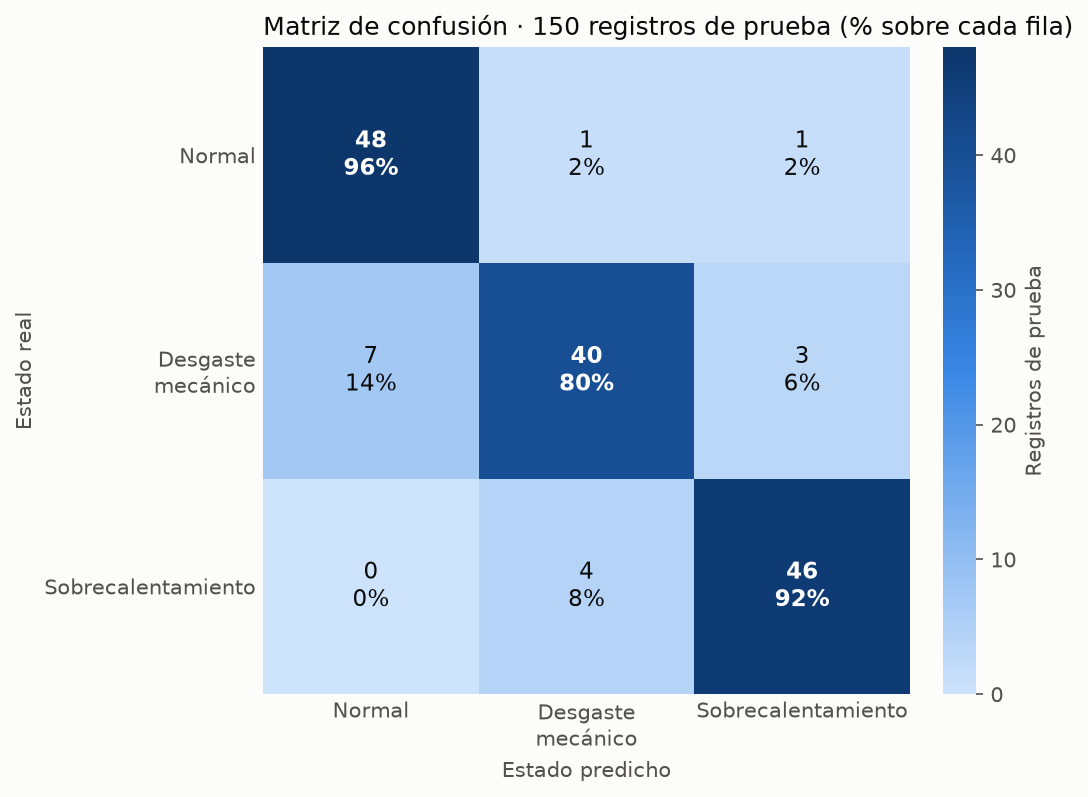

In [24]:
ruta = graficos.matriz_confusion(metricas.matriz, metricas.clases, RUTA_GRAFICOS)
display(Image(filename=ruta))

### ¿Ha salido "afortunado" el reparto? Validación cruzada

El entrenamiento se divide en 5 pliegues estratificados. Cada pliegue se evalúa con un modelo entrenado con los otros 4, repitiendo **todo** el proceso (imputación, normalización y centroides) para que no haya fuga.
También sirve para comprobar, con números reproducibles, si quitar la presión mejora el modelo.

In [25]:
cv = {
    "4 variables (modelo final)": evaluacion.validacion_cruzada(particion.X_entrenamiento, y_entrenamiento),
    "sin presión": evaluacion.validacion_cruzada(particion.X_entrenamiento, y_entrenamiento, columnas=[0, 1, 2]),
    "solo temperatura y vibración": evaluacion.validacion_cruzada(particion.X_entrenamiento, y_entrenamiento, columnas=[0, 1]),
}
evaluacion.mostrar_validacion_cruzada(cv, metricas.accuracy)

Validación cruzada estratificada de 5 pliegues (solo sobre el entrenamiento):
  4 variables (modelo final)     media 0.888 ± 0.027   pliegues [0.867 0.867 0.925 0.908 0.873]
  sin presión                    media 0.893 ± 0.018   pliegues [0.875 0.9   0.908 0.908 0.873]
  solo temperatura y vibración   media 0.870 ± 0.041   pliegues [0.8   0.892 0.867 0.892 0.898]
  Accuracy en la prueba: 0.893  ->  dentro del rango habitual de la validación cruzada (media ± 2 desviaciones)


### Respuestas a las preguntas del enunciado

Las respuestas 1 a 3 se **calculan** a partir de la matriz, así que siempre cuadran con los números. La 4 es la postura defendida: **solo como apoyo**.

In [26]:
evaluacion.responder_preguntas(metricas)

1. Mejores resultados: Sobrecalentamiento (F1 = 0.920, precision 0.920, recall 0.920).
2. Confusión más frecuente: Desgaste mecánico predicho como Normal (7 casos). Errores por pareja, en ambas direcciones: Normal–Desgaste mecánico 8, Desgaste mecánico–Sobrecalentamiento 7, Normal–Sobrecalentamiento 1.
3. Clase con más dificultad: Desgaste mecánico (recall = 0.800): se escapan 10 de 50.
4. Solo como apoyo, no como sistema autónomo. 7 de 100 máquinas con avería (7%) se diagnostican como normales (Desgaste mecánico: 7 de 50; Sobrecalentamiento: 0 de 50) y nadie las revisaría: es el error más caro en mantenimiento. Además, el modelo no da un grado de confianza y se ha evaluado con clases equilibradas, cuando en una fábrica real casi todas las mediciones son normales. Sirve como alerta temprana que prioriza qué máquinas revisar, con la decisión final en manos de una persona.


**Comparado con lo previsto en el apartado 3:** la pareja normal–desgaste es la que más se confunde (8 errores), como se anticipó.
Pero la pareja desgaste–sobrecalentamiento suma casi lo mismo (7), algo que el análisis no destacaba. El desgaste es la única clase que se confunde con las otras dos.